# 05 · Deterministic MPC vs CC-MPC (ODE track)

> **In short:** run full closed loops with sensor noise and model mismatch through `SimulationRunner`, the same engine as `quadrotor-mpc-run`, and compare deterministic MPC with CC-MPC on the same seed.
>
> **Runtime:** about 1 minute (shorter with FAST) · **Read alongside:** [ODE experiments](../2.Code/docs/guides/ode-experiments.md) · [Metrics](../2.Code/docs/reference/metrics.md)

**You will:**

- run paired closed loops on `static_obstacle.yaml`
- compare paths, clearance, chance residual and solve time
- see how δ trades clearance for path length

In [1]:
from nbsetup import *

In [2]:
from quadrotor_mpc.application.simulation.config import load_scenario
from quadrotor_mpc.application.simulation.runner import SimulationRunner
from quadrotor_mpc.control.ccmpc.obstacle import EllipsoidalObstacle

controller_config = CONFIG / "controller.yaml"
scenario = load_scenario(CONFIG / "scenarios" / "static_obstacle.yaml")
results = {
    mode: SimulationRunner(scenario, controller_config, mode=mode, backend="scipy", seed=scenario.seed).run()
    for mode in ("deterministic", "ccmpc")
}
for mode, result in results.items():
    m = result.metrics
    print(f"{CONTROLLER_LABELS[mode]:13s} success={m.success!s:5s} collision={m.collision!s:5s} "
          f"min clearance={m.min_clearance_m:+.3f} m  final error={m.final_error_m:.3f} m  "
          f"p95 solve={m.p95_solver_ms:.0f} ms")

Deterministic success=False collision=True  min clearance=-0.039 m  final error=0.299 m  p95 solve=1062 ms
CC-MPC        success=True  collision=False min clearance=+0.100 m  final error=0.293 m  p95 solve=1061 ms


Same seed, same noise, same mismatched plant. The deterministic controller plans right up to the
obstacle surface, so estimation error and model mismatch push it **inside** (negative clearance).
CC-MPC inflates the obstacle by the propagated uncertainty and keeps a positive margin.

The paths look close in the top view because the ellipsoid is 3-D; clearance is measured in 3-D.
The residual plot shows the smallest residual the controller *predicted* over its horizon (deterministic
mode uses δ = 0.5, i.e. no tightening): a negative value means the plan needed slack.

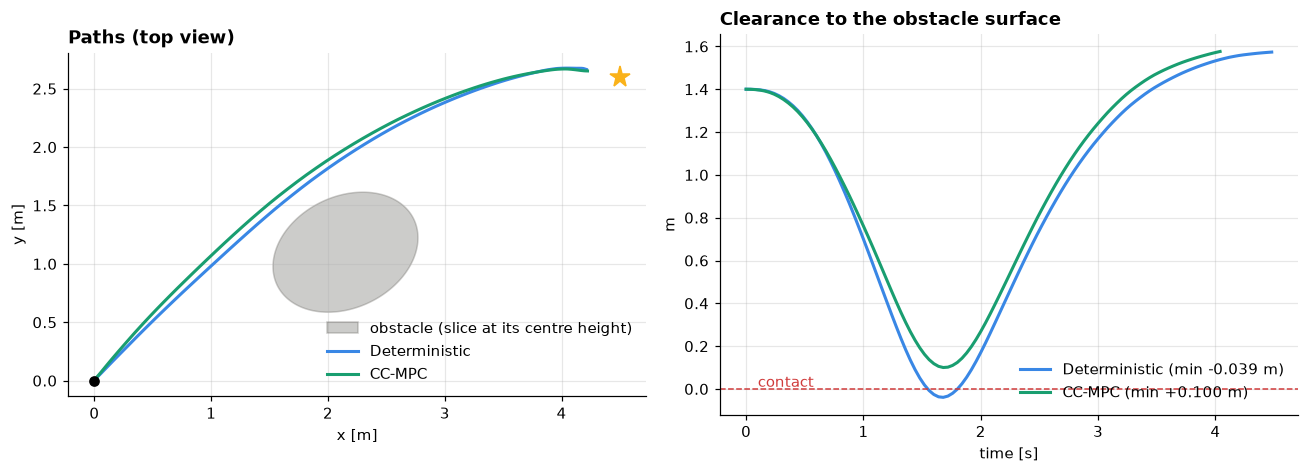

In [3]:
fig, (ax_top, ax_clear) = plt.subplots(1, 2, figsize=(12, 4.4))
spec = scenario.obstacles[0]
omega = EllipsoidalObstacle(position=spec.position, size=spec.size, yaw=spec.yaw).get_omega(0.0)
ax_top.fill(*ellipse_outline(omega, spec.position), color=NEUTRAL, alpha=0.35,
            label="obstacle (slice at its centre height)")
for mode, result in results.items():
    color = CONTROLLER_COLORS[mode]
    ax_top.plot(result.states[:, 0], result.states[:, 1], color=color, lw=2, label=CONTROLLER_LABELS[mode])
    ax_clear.plot(result.times, result.clearances, color=color, lw=2,
                  label=f"{CONTROLLER_LABELS[mode]} (min {np.nanmin(result.clearances):+.3f} m)")
ax_top.plot(*scenario.start[:2], "ko")
ax_top.plot(*scenario.goal[:2], "*", ms=14, color="#fab219")
ax_top.set(title="Paths (top view)", xlabel="x [m]", ylabel="y [m]", aspect="equal")
ax_top.legend(loc="lower right")
ax_clear.axhline(0, color=CRITICAL, ls="--", lw=1)
ax_clear.text(0.1, 0.01, "contact", color=CRITICAL)
ax_clear.set(title="Clearance to the obstacle surface", xlabel="time [s]", ylabel="m")
ax_clear.legend()
plt.tight_layout()
plt.show()

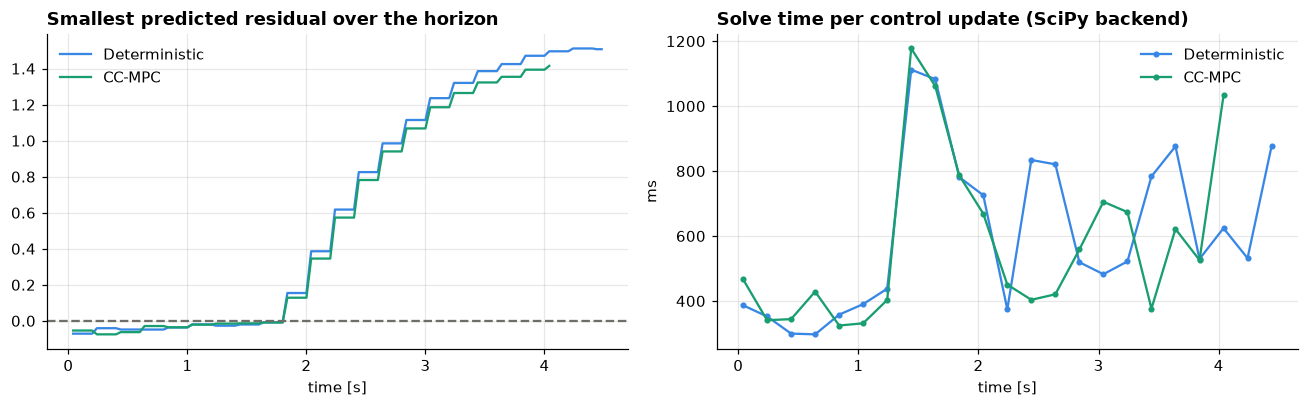

In [4]:
fig, (ax_res, ax_t) = plt.subplots(1, 2, figsize=(12, 3.8))
for mode, result in results.items():
    color = CONTROLLER_COLORS[mode]
    ax_res.plot(result.times, result.chance_residuals, color=color, label=CONTROLLER_LABELS[mode])
    updates = result.solver_times_ms > 0  # the controller runs every 0.2 s, the plant every 0.04 s
    ax_t.plot(result.times[updates], result.solver_times_ms[updates], "o-", ms=3, color=color,
              label=CONTROLLER_LABELS[mode])
ax_res.axhline(0, color=NEUTRAL, ls="--")
ax_res.set(title="Smallest predicted residual over the horizon", xlabel="time [s]")
ax_t.set(title="Solve time per control update (SciPy backend)", xlabel="time [s]", ylabel="ms")
ax_res.legend()
ax_t.legend()
plt.tight_layout()
plt.show()

## Risk level δ

Smaller δ means a larger margin. The CVXPY backend is used here because it is faster.

delta=0.01: min clearance +0.178 m, path 5.44 m, success=True


delta=0.05: min clearance +0.128 m, path 5.40 m, success=True


delta=0.20: min clearance +0.069 m, path 5.36 m, success=True


delta=0.45: min clearance +0.019 m, path 5.33 m, success=True


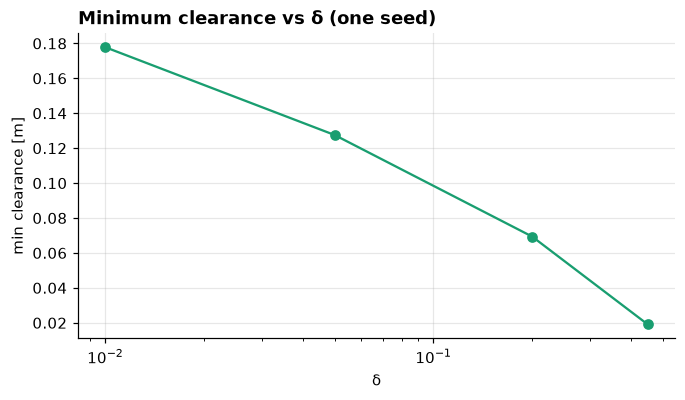

In [5]:
deltas = [0.03, 0.20] if FAST else [0.01, 0.05, 0.20, 0.45]
rows = []
for delta in deltas:
    run = SimulationRunner(scenario, controller_config, mode="ccmpc", backend="cvxpy", seed=scenario.seed,
                           controller_override={"controller": {"obstacle": {"delta": delta}}}).run()
    rows.append((delta, run.metrics.min_clearance_m, run.metrics.path_length_m, run.metrics.success))
    print(f"delta={delta:.2f}: min clearance {run.metrics.min_clearance_m:+.3f} m, "
          f"path {run.metrics.path_length_m:.2f} m, success={run.metrics.success}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color=CONTROLLER_COLORS["ccmpc"])
ax.set(title="Minimum clearance vs δ (one seed)", xlabel="δ", ylabel="min clearance [m]", xscale="log")
plt.show()

## Takeaways

- One seed is a diagnostic, not evidence. For statistics run `quadrotor-mpc-run --compare --trials 30`
  or the sweep command in the [ODE experiments guide](../2.Code/docs/guides/ode-experiments.md).
- The SciPy backend is slow (about 1 s per update); it is for teaching and CI, not real time.
- The rest of the track moves to the 13-state native pipeline used for validation.

---

**Previous:** [04_chance_constraints.ipynb](04_chance_constraints.ipynb) · **Next:** [06_native_estimation.ipynb](06_native_estimation.ipynb)